![The Bridge - Matplotlib](../img/banner_thebridge_matplotlib.png)

# Visualización con Matplotlib: Algunos elementos de apoyo

En esta sesión vamos a trabajar con las leyendas y los textos añadidos, y veremos cómo marcar con flechas y señalar algunas zonas importantes de nuestras figuras y gráficas. Empecemos importando lo necesario:

In [1]:
# %matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8-whitegrid')

### Manipulando leyendas


Recordemos cómo se creaba una leyenda: básicamente, añadíamos una etiqueta a las gráficas y luego llamábamos a la función `plt.legend`:

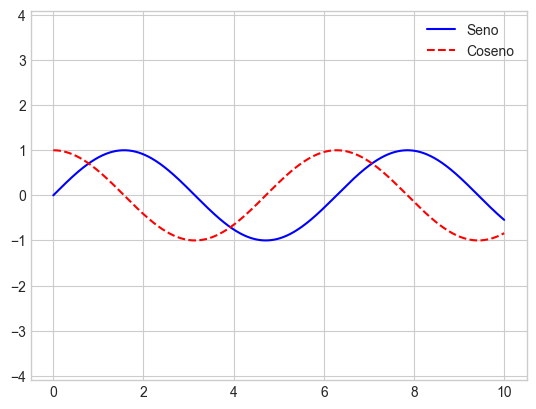

In [2]:
x = np.linspace(0, 10, 1000)
fig, ax = plt.subplots()
ax.plot(x, np.sin(x), '-b', label='Seno')
ax.plot(x, np.cos(x), '--r', label='Coseno')
ax.axis('equal')  # misma escala en x e y
ax.legend();

Y vamos a ver cómo:
* Ponerle título, con el argumento `title`
* Cambiar la posición de la leyenda, con el argumento `loc`
* Quitar el marco y ponerlo con el argumento `frameon`
* Indicar el número de columnas de la leyenda con `ncol`

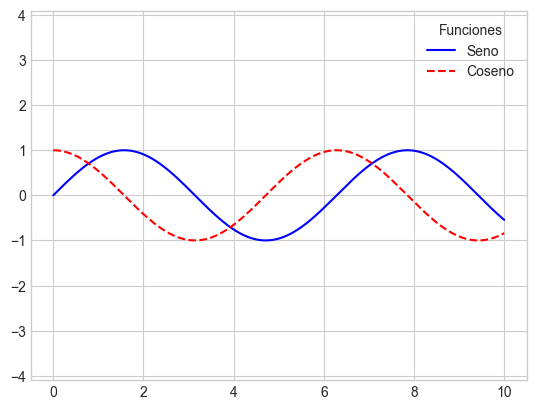

In [3]:
# Título
ax.legend(title='Funciones')
fig

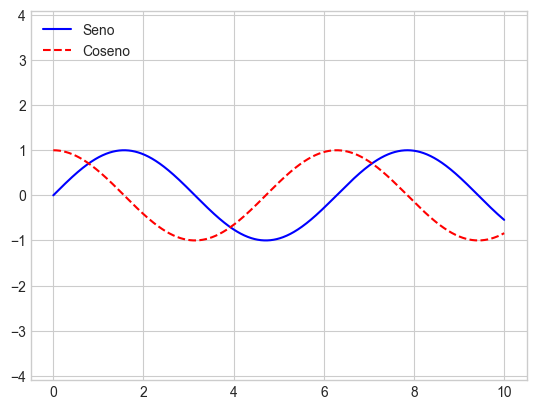

In [4]:
# Posición: 'upper center', 'lower left', 'best' (por defecto)...
ax.legend(loc='upper left')
fig

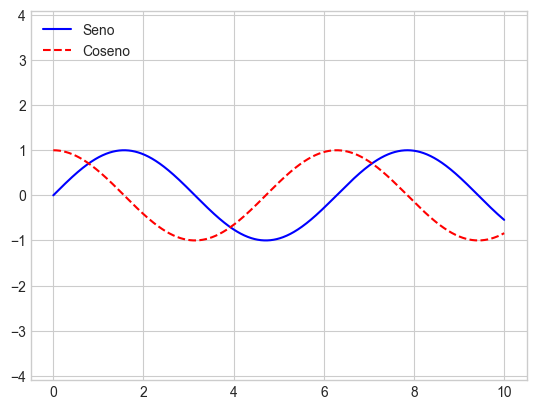

In [5]:
# Sin marco
ax.legend(loc='upper left', frameon=False)
fig

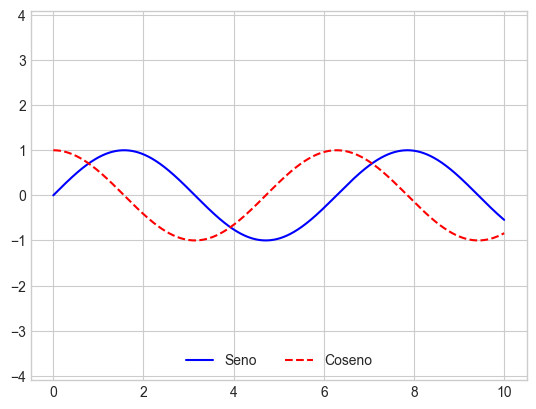

In [6]:
# Número de columnas
ax.legend(loc='lower center', frameon=False, ncol=2)
fig

#### Truquitos (I): Leyendas para el tamaño de los puntos [y pequeño repaso]

A veces, los valores predeterminados de la leyenda no son suficientes para la visualización dada.
Por ejemplo, tal vez estés utilizando el tamaño de los puntos para marcar ciertas características de los datos, y quieras crear una leyenda que refleje esto.  Además, aprenderemos algo sobre la barra de colores (*colorbar*).

Aquí tienes un ejemplo donde usaremos el tamaño de los puntos para indicar las poblaciones de las ciudades de California.
Nos gustaría una leyenda que especifique la escala de los tamaños de los puntos, y lo lograremos trazando algunos datos etiquetados sin entradas:


In [7]:
# Leer dataframe
cities = pd.read_csv('../data/california_cities.csv')
cities.head()

,Unnamed: 0,city,latd,longd,elevation_m,elevation_ft,population_total,area_total_sq_mi,area_land_sq_mi,area_water_sq_mi,area_total_km2,area_land_km2,area_water_km2,area_water_percent
0,0,Adelanto,34.576111,-117.432778,875.0,2871.0,31765,56.027,56.009,0.018,145.107,145.062,0.046,0.03
1,1,AgouraHills,34.153333,-118.761667,281.0,922.0,20330,7.822,7.793,0.029,20.260,20.184,0.076,0.37
2,2,Alameda,37.756111,-122.274444,NaN,33.0,75467,22.960,10.611,12.349,59.465,27.482,31.983,53.79
3,3,Albany,37.886944,-122.297778,NaN,43.0,18969,5.465,1.788,3.677,14.155,4.632,9.524,67.28
4,4,Alhambra,34.081944,-118.135000,150.0,492.0,83089,7.632,7.631,0.001,19.766,19.763,0.003,0.01


Practiquemos además un poco con todo lo aprendido en las sesiones anteriores:

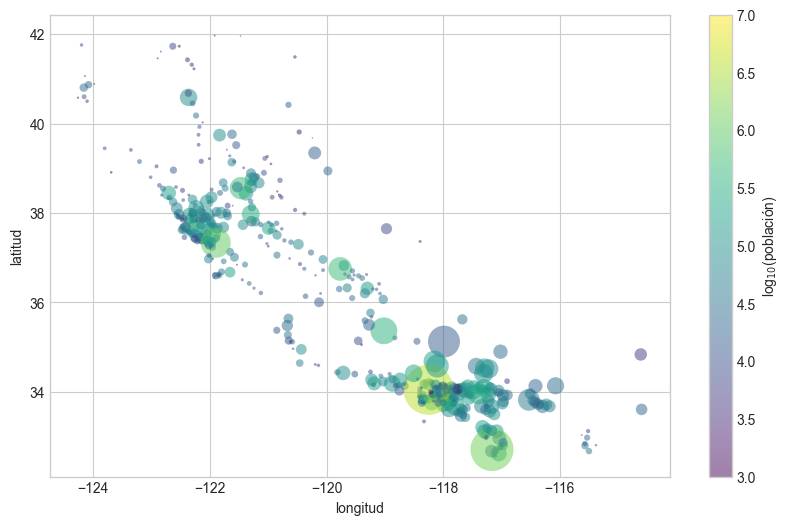

In [8]:
# Dispersión, barra de colores
lat, lon = cities['latd'], cities['longd']
population, area = cities['population_total'], cities['area_total_km2']

plt.figure(figsize=(10, 6))
plt.scatter(lon, lat, c=np.log10(population), cmap='viridis',
            s=area, linewidth=0, alpha=0.5)
plt.xlabel('longitud')
plt.ylabel('latitud')
plt.colorbar(label='log$_{10}$(población)')
plt.clim(3, 7);

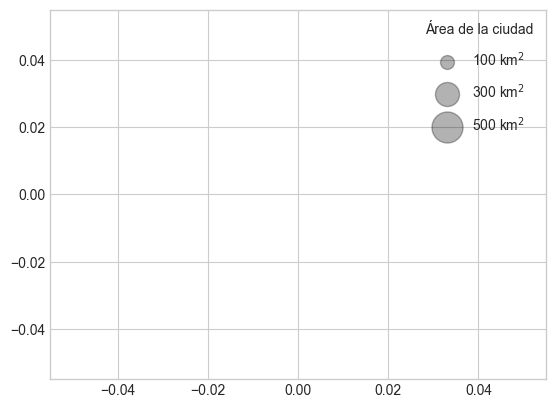

In [9]:
# Fake legend: pintamos listas vacías con el tamaño y la etiqueta que queremos que aparezcan en la leyenda
for area_ref in [100, 300, 500]:
    plt.scatter([], [], c='k', alpha=0.3, s=area_ref,
                label=str(area_ref) + ' km$^2$')
plt.legend(scatterpoints=1, frameon=False, labelspacing=1, title='Área de la ciudad');

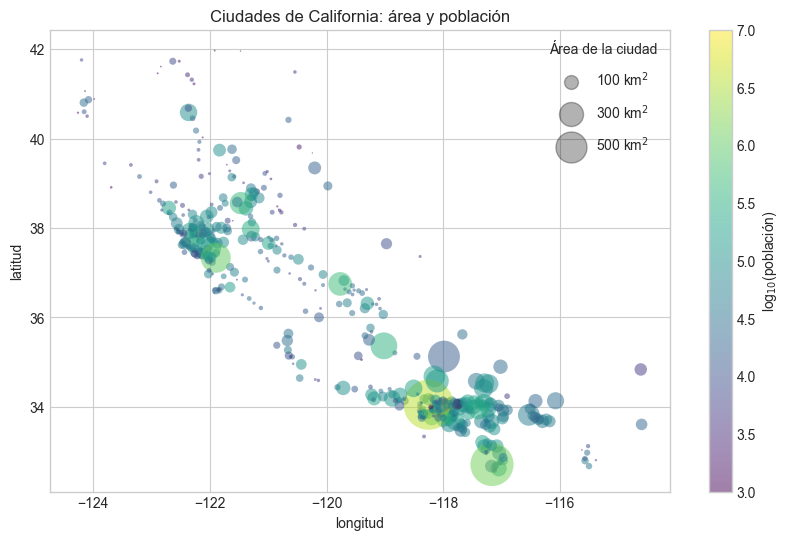

In [10]:
# Todo junto
plt.figure(figsize=(10, 6))
# Puntos con tamaño y color, pero sin etiqueta (label=None)
plt.scatter(lon, lat, label=None,
            c=np.log10(population), cmap='viridis',
            s=area, linewidth=0, alpha=0.5)
plt.xlabel('longitud')
plt.ylabel('latitud')
plt.colorbar(label='log$_{10}$(población)')
plt.clim(3, 7)

# Leyenda con listas vacías
for area_ref in [100, 300, 500]:
    plt.scatter([], [], c='k', alpha=0.3, s=area_ref,
                label=str(area_ref) + ' km$^2$')
plt.legend(scatterpoints=1, frameon=False, labelspacing=1, title='Área de la ciudad')

plt.title('Ciudades de California: área y población');

La leyenda siempre hace referencia a algún objeto que esté en el gráfico, así que si queremos mostrar una forma concreta tenemos que pintarla.
En este caso los objetos que queremos (círculos grises) no están en el gráfico, así que **los falsificamos pintando listas vacías.**
Fíjate también en que la leyenda solo muestra los elementos que tienen una etiqueta (`label`).

### Textos, anotaciones y flechas

#### Texto

Ya lo vimos de pasada al hablar de subplots, para numerarlos. Es sencillo:

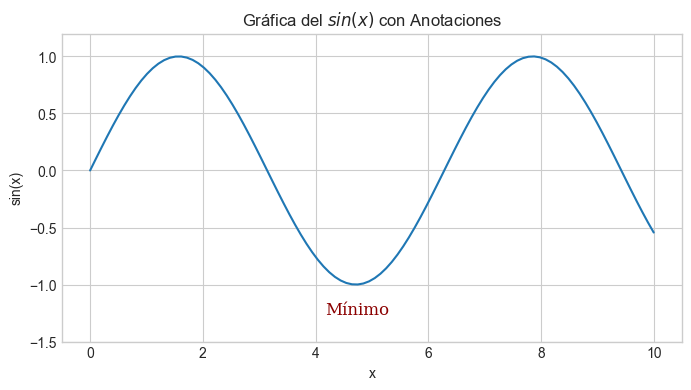

In [11]:
# Generamos una gráfica simple
x = np.linspace(0, 10, 100)
y = np.sin(x)
min_x_value = pd.Series(y, index=x).idxmin()
min_y_value = pd.Series(y, index=x).min()
plt.figure(figsize=(8, 4))
plt.plot(x, y)
plt.title(r"Gráfica del $sin(x)$ con Anotaciones")
plt.xlabel("x")
plt.ylabel("sin(x)")

# Añadir texto en la gráfica: coordenadas (x, y) en unidades de los datos
plt.text(min_x_value, min_y_value - 0.15, "Mínimo", ha='center', va='top',
         fontsize=12, color='darkred', fontfamily='serif')
plt.ylim(-1.5, 1.2);

[Aquí](https://jonathansoma.com/lede/data-studio/matplotlib/list-all-fonts-available-in-matplotlib-plus-samples/) puedes encontrar una lista de fuentes disponibles en Matplotlib (aunque puede que no te funcionen todas). 

Y ahora veamos otra forma de añadir texto con flechas de diversa forma para poder marcar y anotar nuestras gráficas.

#### Flechas y anotaciones

Veamos cómo añadir una anotación no necesariamente donde se produce y marcar ese punto con una flecha. `annotate` coloca el texto en `xytext` y dibuja una flecha hasta el punto `xy`. Aprovechamos también para señalar una zona del eje X con `axvspan`:

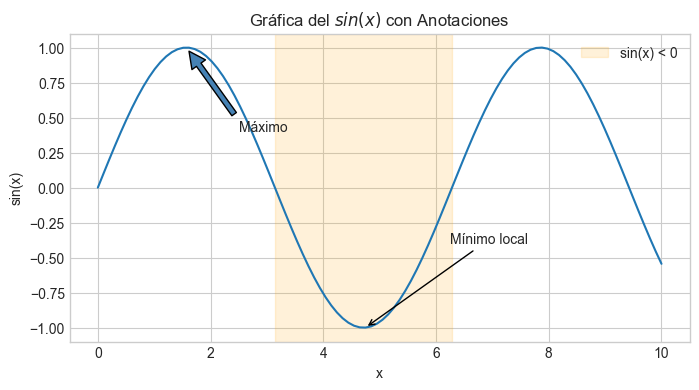

In [12]:
# Repetir la gráfica simple
plt.figure(figsize=(8, 4))
plt.plot(x, y)
plt.title(r"Gráfica del $sin(x)$ con Anotaciones")
plt.xlabel("x")
plt.ylabel("sin(x)")

# Añadir anotación con flecha indicativa
plt.annotate("Mínimo local", xy=(min_x_value, min_y_value),
             xytext=(min_x_value + 1.5, min_y_value + 0.6),
             arrowprops=dict(arrowstyle='->', color='black'))

# Otro estilo de flecha
plt.annotate("Máximo", xy=(np.pi / 2, 1), xytext=(2.5, 0.4),
             arrowprops=dict(facecolor='steelblue', shrink=0.05))

# Señalar una zona
plt.axvspan(np.pi, 2 * np.pi, color='orange', alpha=0.15, label='sin(x) < 0')
plt.legend(loc='upper right');